# **Deep Learning Laboratory 1**
- - -

## ***Question A1:*** In two or three sentences, explain the difference between:
>Git: tool that let you keep track of changes made on your code and save different versions, but it is locally stored.

>GitHub: online platform where you can store and share coding projects, allowing you to collaborate with a team or individuals.

---
## ***Task B1:*** Examine the Python Environment

In [1]:
import sys
print(sys.version)

3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]


In [2]:
import torch
import numpy as np
import pandas as pd
import matplotlib
print("PyTorch:", torch.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Matplotlib:", matplotlib.__version__)

PyTorch: 2.11.0+cu128
NumPy: 2.1.3
Pandas: 2.2.3
Matplotlib: 3.10.0



***Question B1:*** Why is it useful to record software-library versions when performing machine-learning experiments?
> It is useful because different versions can work differently or has other features and can produce different results. If we record the version it makes it easier for reference and reproduce the experiment, as well as finding problems.





---
## ***Part C:*** CPU and GPU Programmin

In [3]:
import torch
device = torch.device(
 "cuda" if torch.cuda.is_available() else "cpu"
)
print("Selected device:", device)

if torch.cuda.is_available():
 print(torch.cuda.get_device_name(0))


Selected device: cuda
Tesla T4


***Question C1:*** What device is your notebook currently using?
> It is using cuda

***Question C2:*** Why might a GPU be useful when training a large neural network?
> A GPU is designed to do many calculations at the same time, therefore when training large models, it is faster.

- - -
##***Part D:*** First PyTorch Tensor

In [4]:
x = torch.tensor([
 [1.0, 2.0, 3.0],
 [4.0, 5.0, 6.0]
])
print(x)

print(x.shape)

torch.Size([2, 3])

print(x + 10)
print(x * 2)
print(x.mean())

tensor([[1., 2., 3.],
        [4., 5., 6.]])
torch.Size([2, 3])
tensor([[11., 12., 13.],
        [14., 15., 16.]])
tensor([[ 2.,  4.,  6.],
        [ 8., 10., 12.]])
tensor(3.5000)


In [5]:
#MATRIX MULTIPLICATION
A = torch.tensor([
 [1.0, 2.0],
 [3.0, 4.0]
])
B = torch.tensor([
 [5.0, 6.0],
 [7.0, 8.0]
])

C = A @ B
print(C)


tensor([[19., 22.],
        [43., 50.]])


***Question D1:*** What is the shape of C?
> The shape is a 2x2

***Question D2:*** Why do you think matrices and tensors might be important in neural networks?
A short intuitive answer is sufficient.
> Matrices and tensors can help to store information (numbers) in an organize manner, and neural networks use numerical data and perform many calclulations, therefore it might be more organize.

---
## ***Part E:*** Moving Data to a GPU

In [6]:
x = x.to(device)
print(x.device)

cuda:0


---
## ***PART G:*** Hugging Face Model Hub

In [7]:
!pip install -q transformers

from transformers import pipeline

classifier = pipeline(
 "image-classification",
 model="google/vit-base-patch16-224"
)

config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

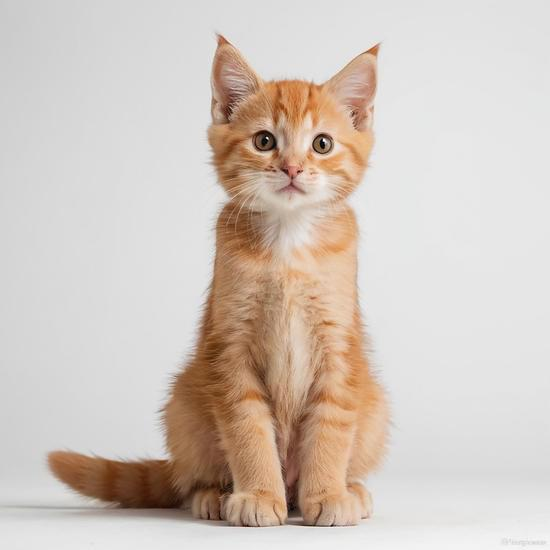

[{'label': 'Egyptian cat', 'score': 0.495433509349823},
 {'label': 'tabby, tabby cat', 'score': 0.2771216630935669},
 {'label': 'tiger cat', 'score': 0.17015641927719116},
 {'label': 'lynx, catamount', 'score': 0.01184422243386507},
 {'label': 'Persian cat', 'score': 0.008686430752277374}]

In [9]:
from PIL import Image
image = Image.open("sample1.jpg")
display(image)

results = classifier(image)
results


---
##***Part H:*** Model Cards

Questions H1–H4
Record the following:
1. What type of model is this?
> Vision Transformer (ViT) model for Image Classification
2. What task was it designed to perform?
>You can use the raw model for image classification
3. What dataset was it trained or fine-tuned on?
>ImageNet (also referred to as ILSVRC2012)
4. What limitations can you identify from the Model Card?
>It might not be accurate since the performance of the model would depend on the image quality, and since it is trained in specific data sets, it might not work properly for every image.


---
## ***PART I:*** Run your First AI Inference

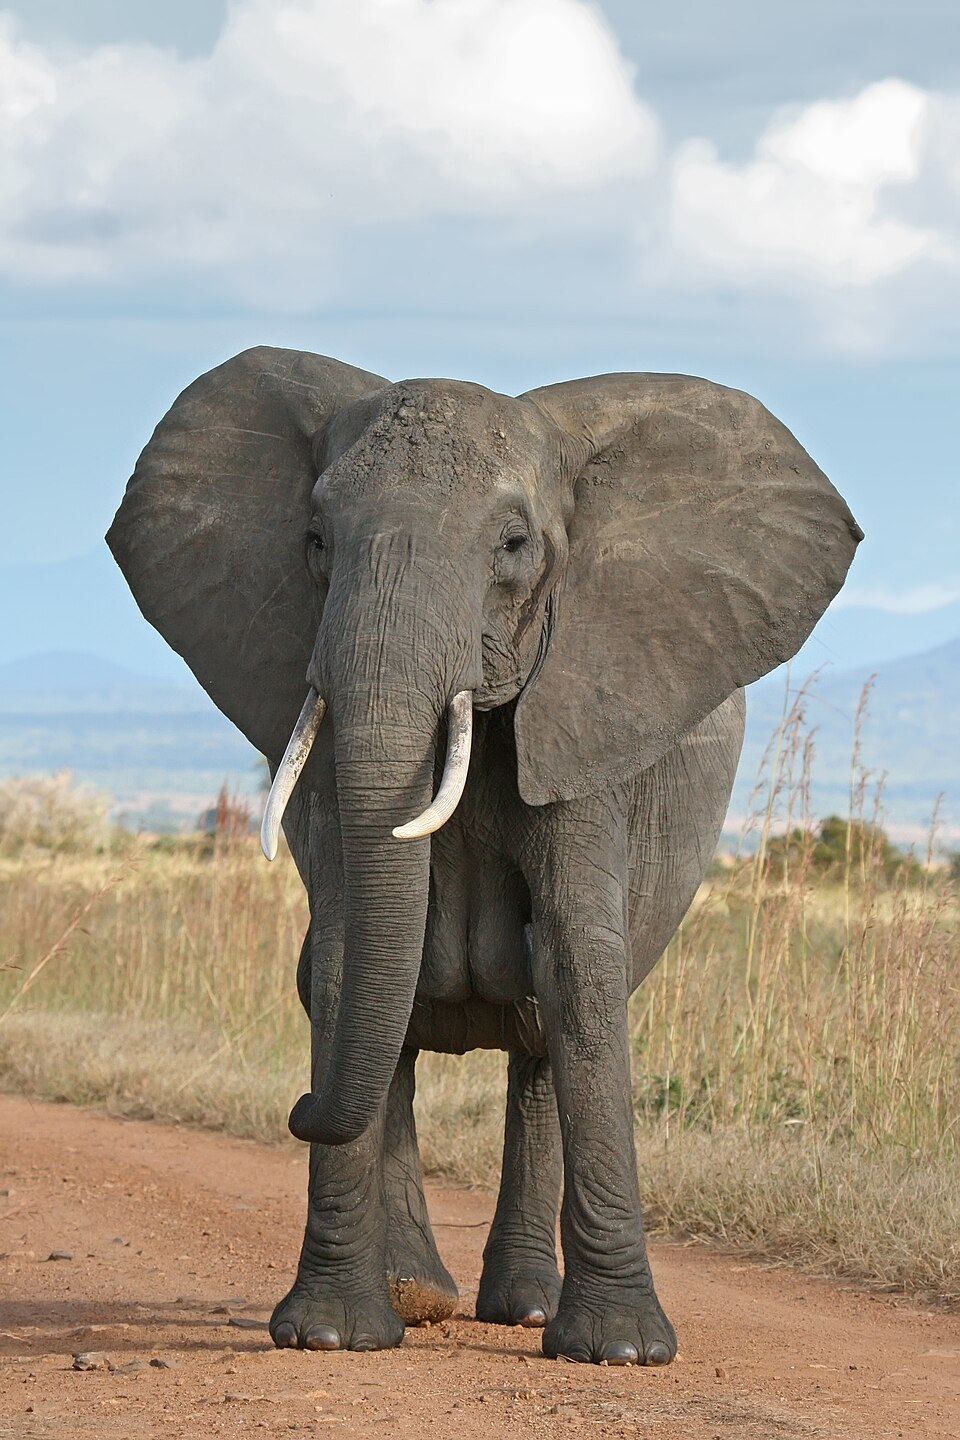

[{'label': 'African elephant, Loxodonta africana', 'score': 0.754142701625824},
 {'label': 'tusker', 'score': 0.23489996790885925},
 {'label': 'Indian elephant, Elephas maximus', 'score': 0.007575297262519598},
 {'label': 'zebra', 'score': 0.0009113976848311722},
 {'label': 'warthog', 'score': 0.00024650085833854973}]

In [10]:
from PIL import Image
image = Image.open("sample2.jpg")
display(image)

results = classifier(image)
results


## ***Part J:*** Experiment with new Images

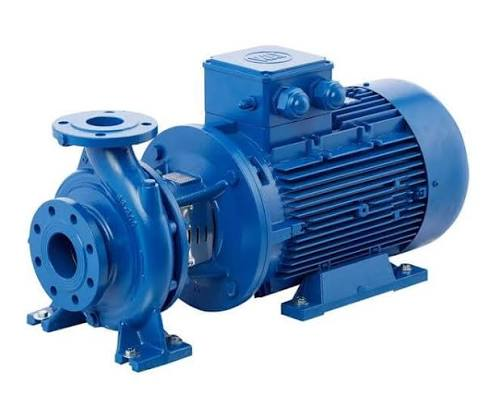

[{'label': 'piggy bank, penny bank', 'score': 0.1022796705365181}, {'label': 'oil filter', 'score': 0.06665705144405365}, {'label': 'electric fan, blower', 'score': 0.028874974697828293}, {'label': 'vacuum, vacuum cleaner', 'score': 0.015854662284255028}, {'label': 'mousetrap', 'score': 0.015502450987696648}]


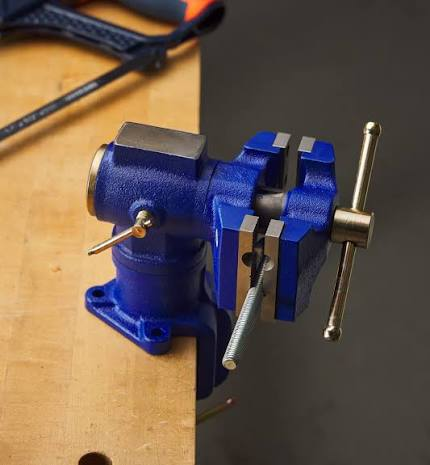

[{'label': "plane, carpenter's plane, woodworking plane", 'score': 0.6189603209495544}, {'label': 'screwdriver', 'score': 0.19834506511688232}, {'label': "carpenter's kit, tool kit", 'score': 0.04466455802321434}, {'label': 'hammer', 'score': 0.028690963983535767}, {'label': 'nail', 'score': 0.02300814352929592}]


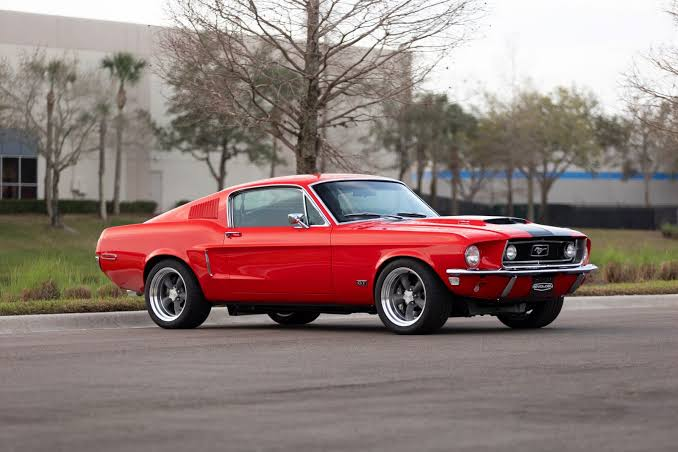

[{'label': 'sports car, sport car', 'score': 0.6508292555809021}, {'label': 'car wheel', 'score': 0.14085468649864197}, {'label': 'racer, race car, racing car', 'score': 0.08080054819583893}, {'label': 'pickup, pickup truck', 'score': 0.0541539303958416}, {'label': 'convertible', 'score': 0.02545410767197609}]


In [11]:
from PIL import Image

images = ["image1.jpg", "image2.jpg", "image3.jpg"]

for image_path in images:
    image = Image.open(image_path)

    display(image)

    results = classifier(image)

    print(results)

***Results***

| Image | Prediction 1 | Score 1 | Prediction 2 | Score 2 | Prediction 3 | Score 3 |
|-------|---------------|---------|---------------|---------|---------------|---------|
| Image 1 |piggy bank|0.10227|oil filter|0.06665|electric fan|0.028874|
| Image 2 |carpenter's plane|0.61896|screwdriver|0.198345|carpenter's kit|0.0446645|
| Image 3 |sports car|0.6508292|car wheel|0.140854|racer|0.0808005|

## ***Part K:*** Make the model fail

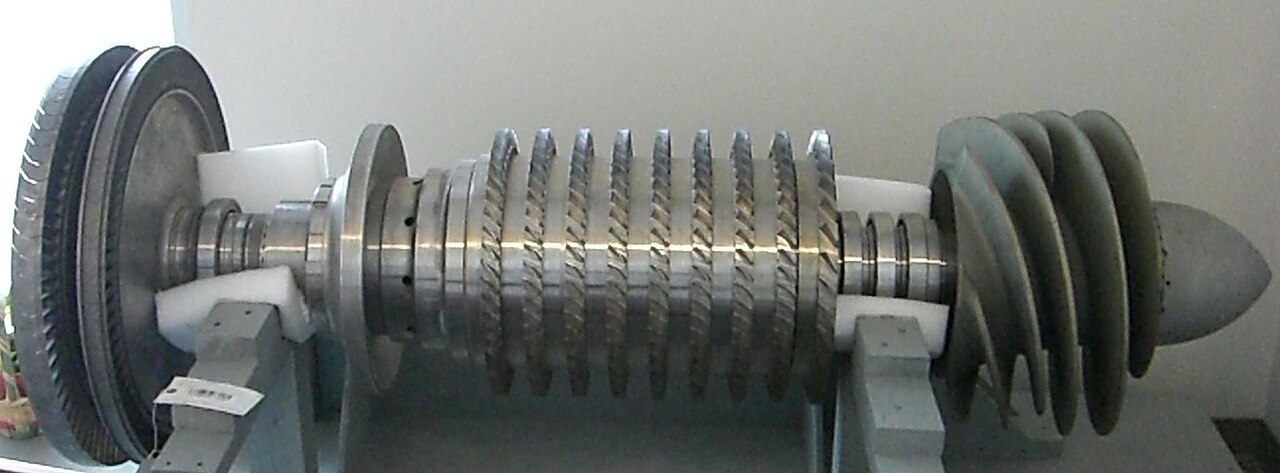

[{'label': 'dumbbell', 'score': 0.4787982106208801},
 {'label': 'barbell', 'score': 0.19663597643375397},
 {'label': 'reel', 'score': 0.08787788450717926},
 {'label': 'plate rack', 'score': 0.030350763350725174},
 {'label': 'coil, spiral, volute, whorl, helix',
  'score': 0.023097625002264977}]

In [15]:
from PIL import Image
image = Image.open("test1.jpg")
display(image)

results = classifier(image)
results

Questions K1–K3
1. What did the model predict?
>The model predicted a dumbbell
2. What should the correct interpretation have been?
>  axial turbopump for M-1 rocket engine.
3. Why do you think the model might have failed?
> The model is clearly not trained for any complex machinery. Also, quality of the image is not too clear and close to the subject, which makes it analyze the biggest left and right components of the turbopump as a dumbbell

---
## ***Part L:*** Confidence is not correctness

Question L1:
Can you find an example in which the model gives a reasonably high score to an incorrect or questionable prediction?
> When I added a “wristwatch” image, it obtained a score of 90.4% for a "stopwatch". This shows that a high score does not mean that the answer is accurate or correct.


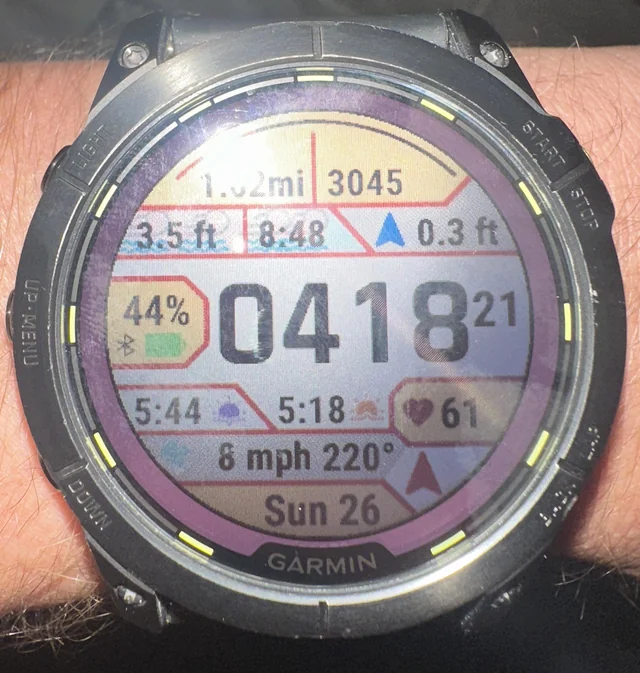

[{'label': 'stopwatch, stop watch', 'score': 0.9043319821357727},
 {'label': 'digital watch', 'score': 0.045982953161001205},
 {'label': 'barometer', 'score': 0.020413532853126526},
 {'label': 'magnetic compass', 'score': 0.020338021218776703},
 {'label': 'odometer, hodometer, mileometer, milometer',
  'score': 0.0032812932040542364}]

In [18]:
from PIL import Image
image = Image.open("conf1.jpg")
display(image)

results = classifier(image)
results

## Reflection
This lab helps to understand the basics of deep learning, from setting up the environment depending on your neeeds (GPU/CPU) and using pre-trained models to check the accuraccy of the predictions. It also, instructed us on how to set up a github account for a better workflow.